<a href="https://colab.research.google.com/github/Ahiraf/AegisEarth/blob/main/06_Bell_States_Qsphere_Phase_Oracles.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

### **Bloch Sphere is only useful for single qubit system. For representing multiple qubits one can use multiple bloch sphere but only when those states are unentangled. But when states are entangled We have to use Qsphere rather than Bloch Sphere.**

In [1]:
!pip install qiskit

In [2]:
from qiskit import QuantumCircuit
from qiskit.visualization import plot_state_qsphere, plot_histogram

In [3]:
from qiskit.quantum_info import Statevector

In [4]:
!pip install pylatexenc # always after installing this restart the session

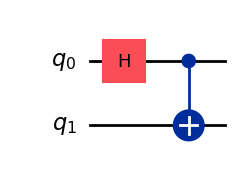

In [5]:
mycircuit = QuantumCircuit(2)
mycircuit.h(0)
mycircuit.cx(0, 1)
mycircuit.draw('mpl')

###**Qiskit by default initializes all the states from |0> state.**

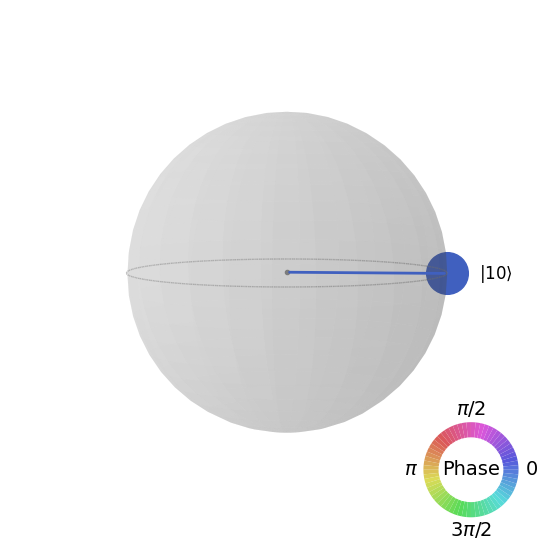

In [6]:
sv = Statevector.from_label('10')
plot_state_qsphere(sv.data)

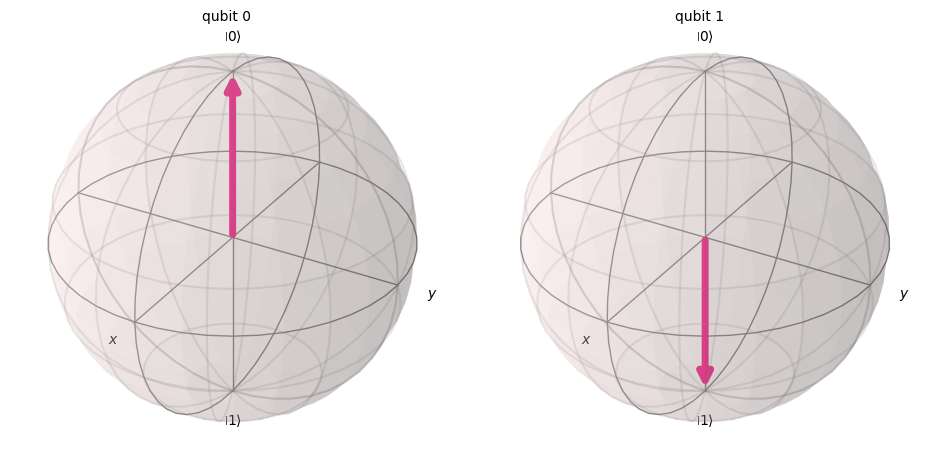

In [7]:
from qiskit.visualization import plot_bloch_multivector
plot_bloch_multivector(sv)

###**So it can be seen that qiskit labels from the right side. From right side of '10' it has named |0> state as qubit 0 and then |1> as qubit 1**

In [8]:
newsv = sv.evolve(mycircuit)
newsv

Statevector([0.        +0.j, 0.70710678+0.j, 0.70710678+0.j,
             0.        +0.j],
            dims=(2, 2))


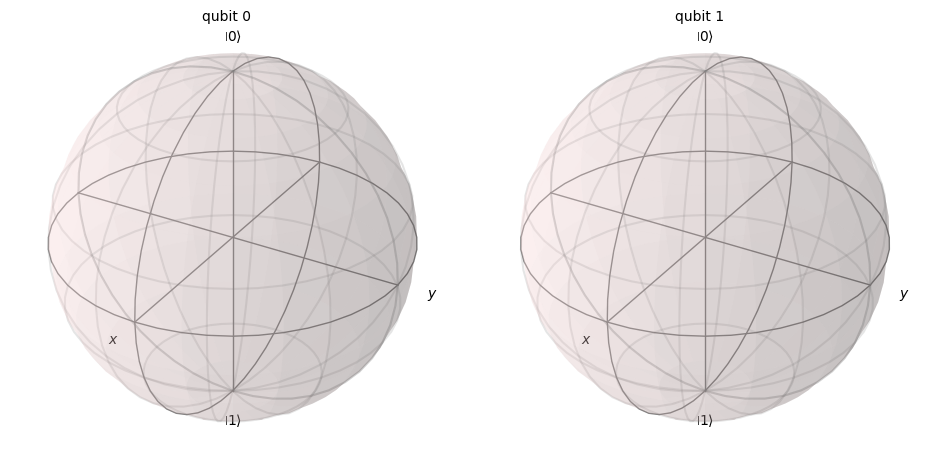

In [9]:
plot_bloch_multivector(newsv)

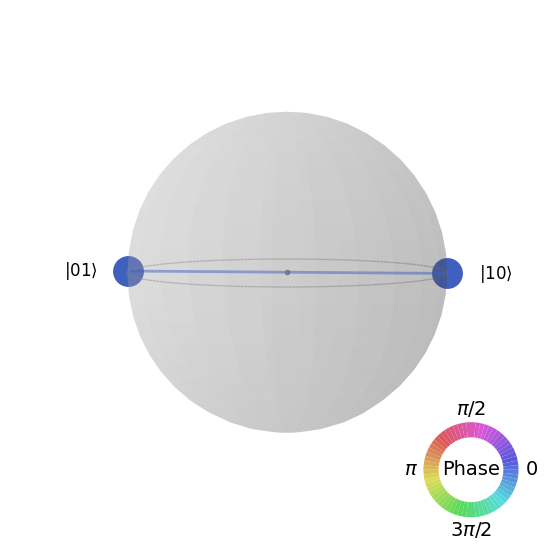

In [10]:
plot_state_qsphere(newsv.data)

### **Means superposition of |01> and |10> states.Their amplitudes are also same.**

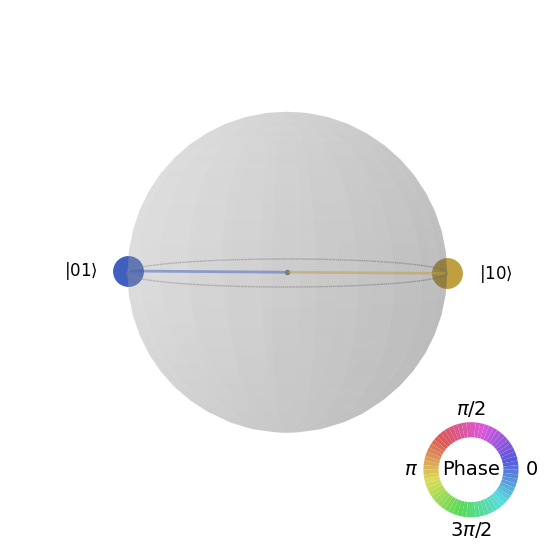

In [11]:
sv1 = Statevector.from_label('11')
newsv1 = sv1.evolve(mycircuit)
newsv1
plot_state_qsphere(newsv1.data)

### **Now |01> is with phase pi which means -1**

# **Adding Measurement Gate**

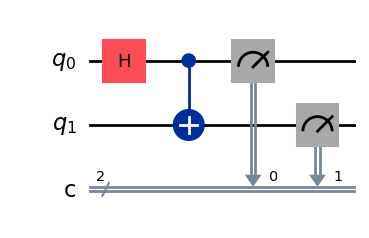

In [12]:
mycircuit1 = QuantumCircuit(2, 2) # Here the first 2 represents 2 Qubits and the second 2 represents 2 Classical bits.
mycircuit1.h(0)
mycircuit1.cx(0, 1)

mycircuit1.measure(0, 0) # it means measurement of qubit 0 should go to classical bit 0
mycircuit1.measure(1, 1) # it means measurement of qubit 1 should go to classical bit 1

mycircuit1.draw('mpl')

# **Simulation**

In [13]:
!pip install qiskit-aer

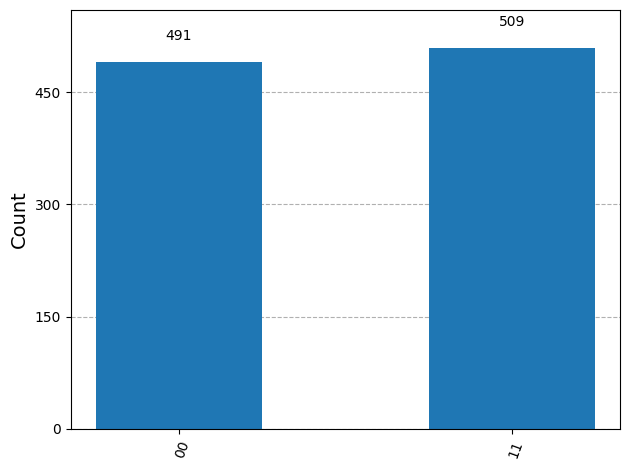

In [19]:
from qiskit_aer import Aer

simulator = Aer.get_backend('qasm_simulator') # This simulator is provided by IBM in this qiskit package. This can simulate upto 32 qubits.
job = simulator.run(mycircuit1, shots=1000)# Shots mean how many time will we use this simulator
result = job.result()
counts = result.get_counts(mycircuit1)
plot_histogram(counts)